# Sedov Blast test for Peano SPH


In this notebook, we set up the Sedov-Taylor Blast test, which is part of a battery of well-established tests for SPH codes.

In this test, particles are initialised at rest in regular grid configuration and periodic BC. Gas has negligible presure. Energy ($E$) is injected to a (or group of) central particle and the blast should propagate isotropically, up to boundary effects. See, e.g., Springel and Hernquist, Mon. Not. R. Astron. Soc. 333, 649–664 (2002).

The wave propagates away from the center according to the following solution
\begin{align}
R(t)=\beta(\gamma)\left(\frac{E_{\rm ini}t^2}{\rho_{\rm ini}}\right)^{1/5}
\end{align}
The solution depends on various integrals that are evaluated numerically.


## Particle behaviour

As usual, in peano 4 the particle-particle interactions are handled in terms of the active and local particle sets. Notice that in this we now do not simply rely on the particles of the adjacent vertices of a cell -- see the sketch below. To understand what the individual particles in the sketch are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

**Remarks**:
- For particle-particle interactions: bear in mind that the local set is a subset of the active set, so be careful about any unwanted self-interactions.
- In this scheme, the following relation should be satisfied:

\begin{align}
H_{\rm SPH} \leq R^{\rm peano}_{\rm cutoff} \leq \frac{\Delta x}{2}\,,
\end{align}

where $H_{\rm SPH}$($\equiv\gamma_K h$) is the SPH interaction radius, $R^{\rm peano}_{\rm cutoff}$ is the internal cut-off radius and $\Delta x$ the cell size.

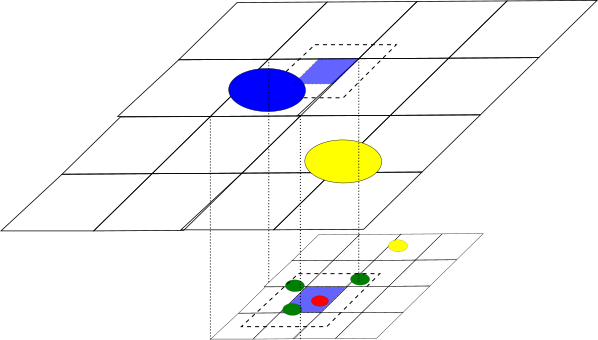

In [1]:
from IPython.display import Image
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

In [2]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

DaStGen 2 (C) www.peano-framework.org
Peano 4 (C) www.peano-framework.org


In [3]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-peano-test-sedov", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertParticlesAlongCartesianLayoutIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/DensityNonSym.o ./observers/DensityNonSym2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleAMR3.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/DensityNonSym.o ./actions/HydroPrepareGradient.o ./observers/HydroPrepareGradient2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/HydroPrepareGradient2peano4_toolbox_part

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [4]:
build_mode = peano4.output.CompileMode.Asserts
#build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured --no-create --no-recursion

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDime

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:
- Velocity array (${\bf v}$)
- Acceleration array (${\bf a}\equiv{\rm d}{\bf v}/{\rm d}t$)
- Mass
- Density
- Pressure
- Internal Energy ($u$)
- Time derivative of internal energy (${\rm d}u/{\rm d}t$)
- Kernel smoothing length ($h$)

We add a marker to indicate the next calculation step required for a particle so we don't perform the same step on a particle twice in a row.

We also add an array to store the new position of a particle after a timestep is completed. We will use this to move the particle at the start of the subsequent timestep.

In [5]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
a_attr = peano4.dastgen2.Peano4DoubleArray("a","Dimensions")
a_prev_step_attr = peano4.dastgen2.Peano4DoubleArray("a_prev_step","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
uDot_attr    = dastgen2.attributes.Double("uDot")
rhoDot_attr  = dastgen2.attributes.Double("rhoDot")
soundSpeed_attr = dastgen2.attributes.Double("soundSpeed")
wcount_attr   = dastgen2.attributes.Double("wcount")
wcount_dh_attr= dastgen2.attributes.Double("wcount_dh")
Ncount_attr   = dastgen2.attributes.Integer("Ncount")

# Variable smoothing length scheme
Omega_attr = dastgen2.attributes.Double("Omega")
rho_dh_attr= dastgen2.attributes.Double("rho_dh")
hDot_attr  = dastgen2.attributes.Double("hDot")

# Artificial viscosity scheme
#rot_v_attr = peano4.dastgen2.Peano4DoubleArray("rot_v","Dimensions")
rot_v_attr    = dastgen2.attributes.Double("rot_v")    # For 2D sims it only has 1 component (z)
div_v_attr    = dastgen2.attributes.Double("div_v")
div_v_dt_attr = dastgen2.attributes.Double("div_v_dt")
div_v_prev_step_attr = dastgen2.attributes.Double("div_v_prev_step")
alpha_AV_attr = dastgen2.attributes.Double("alpha_AV")
v_sig_AV_attr = dastgen2.attributes.Double("v_sig_AV")

alpha_AV_max_ngb_attr = dastgen2.attributes.Double("alpha_AV_max_ngb")
balsara_attr  = dastgen2.attributes.Double("balsara")

# Thermal diffusion scheme
laplace_u_attr = dastgen2.attributes.Double("laplace_u")
alpha_D_attr   = dastgen2.attributes.Double("alpha_D")

# Needed?
has_been_kicked_attr = dastgen2.attributes.Boolean("hasBeenKicked")
has_converged_attr= dastgen2.attributes.Boolean("hasConverged")
smoothL_prev_attr = dastgen2.attributes.Double("smoothingLengthPrevious")

# Debug
timeStep_attr     = dastgen2.attributes.Double("timeStepSize")

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(a_attr)
particle.data.add_attribute(a_prev_step_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
particle.data.add_attribute(uDot_attr)
particle.data.add_attribute(smoothL_attr)
particle.data.add_attribute(rhoDot_attr)
particle.data.add_attribute(Ncount_attr)
particle.data.add_attribute(wcount_attr)
particle.data.add_attribute(wcount_dh_attr)
particle.data.add_attribute(soundSpeed_attr)

# For variable smoothing length
particle.data.add_attribute(Omega_attr)
particle.data.add_attribute(rho_dh_attr)
particle.data.add_attribute(hDot_attr)

# Artificial viscosity
particle.data.add_attribute(rot_v_attr)
particle.data.add_attribute(div_v_attr)
particle.data.add_attribute(div_v_dt_attr)
particle.data.add_attribute(div_v_prev_step_attr)
particle.data.add_attribute(alpha_AV_attr)
particle.data.add_attribute(v_sig_AV_attr)
particle.data.add_attribute(alpha_AV_max_ngb_attr)
particle.data.add_attribute(balsara_attr)

# Thermal difussion
particle.data.add_attribute(laplace_u_attr)
particle.data.add_attribute(alpha_D_attr)

particle.data.add_attribute(timeStep_attr)


# Needed?
particle.data.add_attribute(has_been_kicked_attr)
particle.data.add_attribute(has_converged_attr)
particle.data.add_attribute(smoothL_prev_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [6]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants and parameters

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [7]:
Dimensions = 2
project.output.makefile.set_dimension(Dimensions)

In [8]:
from numpy import pi

GLOBAL_TIME_STEP_SIZE = "1e-3"

# Maximum allowed number of Newton-Raphson iterations
HYDRO_DEFAULT_MAX_ITERATIONS = "5"

# Min and max values for the smoothing length (h) in code units.
#SMOOTH_H_MAX = 
#SMOOTH_H_MIN = 

# Time-integration parameters
CFL_CONSTANT = "0.2"

# EoS parameter
GAMMA = str(5./3.)

# SPH kernel parameters
KERNEL_SUPPORT_RAD = "2"  # "gamma" parameter. =2 for Cubic Spline. Different in other kernels.

# Artificial viscosity parameters
ALPHA_AV_MIN= "0"
ALPHA_AV_MAX= "2"
BETA_AV = "3"       # =3 in SPHENIX
LENGTH_AV = "0.05"

# Thermal difussion
ALPHA_D_MIN = "0"
ALPHA_D_MAX = "1"
BETA_D = "1"

# Smoothing-length free parameter (resolution "eta_neighbours"). 
# Can be set by specifying a desired number of neighbours.
if(Dimensions==2):
    N_ngbs_mean = 10.0  
#    N_ngbs_mean = 20.0  
    SMOOTH_L_FAC = str( (1.   /pi*N_ngbs_mean)**(1./2.)/float(KERNEL_SUPPORT_RAD) ) 
elif(Dimensions==3):
    N_ngbs_mean = 57.9
    SMOOTH_L_FAC = str( (3./4./pi*N_ngbs_mean)**(1./3.)/float(KERNEL_SUPPORT_RAD) ) 

# Kernel root value 
if(Dimensions==2):
    CUBIC_SPLINE_SIGMA = str(10/(7*pi))
elif(Dimensions==3):
    CUBIC_SPLINE_SIGMA = str(1/pi)

print("Smoothing length free factor: " + SMOOTH_L_FAC)
print("Kernel Root value (sigma): " + CUBIC_SPLINE_SIGMA)

# parameters specific to a given problem (e.g., Sedov blast, Sod wave, ...)
BLAST_CENTER = "0.5"    # {0.5,0.5}
#BLAST_ENERGY = "0.02"
BLAST_ENERGY = "1.0"
SPIKE_RADIUS = "0.02"

project.constants.export_const_with_type("GLOBAL_TIME_STEP_SIZE", GLOBAL_TIME_STEP_SIZE, "double")
project.constants.export_const_with_type("HYDRO_DEFAULT_MAX_ITERATIONS", HYDRO_DEFAULT_MAX_ITERATIONS, "int")
project.constants.export_const_with_type("KERNEL_SUPPORT_RAD"   , KERNEL_SUPPORT_RAD   , "double")
project.constants.export_const_with_type("SMOOTH_L_FAC"         , SMOOTH_L_FAC         , "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA"   , CUBIC_SPLINE_SIGMA   , "double")
project.constants.export_const_with_type("BLAST_CENTER", BLAST_CENTER, "double")
project.constants.export_const_with_type("BLAST_ENERGY", BLAST_ENERGY, "double")
project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")
project.constants.export_const_with_type("CFL_CONSTANT", CFL_CONSTANT, "double")
project.constants.export_const_with_type("GAMMA"       , GAMMA       , "double")
project.constants.export_const_with_type("ALPHA_AV_MIN", ALPHA_AV_MIN, "double")
project.constants.export_const_with_type("ALPHA_AV_MAX", ALPHA_AV_MAX, "double")
project.constants.export_const_with_type("BETA_AV"     , BETA_AV     , "double")
project.constants.export_const_with_type("LENGTH_AV"   , LENGTH_AV   , "double")
project.constants.export_const_with_type("ALPHA_D_MIN" , ALPHA_D_MIN , "double")
project.constants.export_const_with_type("ALPHA_D_MAX" , ALPHA_D_MAX , "double")
project.constants.export_const_with_type("BETA_D"      , BETA_D      , "double")

Smoothing length free factor: 0.8920620580763856
Kernel Root value (sigma): 0.4547284088339867


## Model the setup phases

## Initialize regular grid

In [9]:
mesh_size = 0.5

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [10]:
initialisation_snippet = """
 
 /*
  * Initial Conditions for the particular SPH test
  * 
  * 1. Sedov Blast: particles are initialised at rest in regular grid configuration and periodic BC. 
  * Energy is injected to a (or group of) central particle and the blast should propagate
  * isotropically, up to boundary effects.
  * See, e.g., Springel and Hernquist, Mon. Not. R. Astron. Soc. 333, 649–664 (2002).
  *
  */
  
 // Internal cutoff radious used by Peano. Should always be larger than actual SPH cutoff radious (2h).
 particle->setCutOffRadius(0.16);
 
 particle->setDensity ( 1.0 );        
// particle->setMass    ( particle->getDensity()/400/2.56069 );       
 particle->setMass    ( particle->getDensity()/400/2.56069 );       
 particle->setPressure( 1e-6);
 
 particle->setSmoothingLength( SMOOTH_L_FAC * std::pow(particle->getMass()/particle->getDensity(), 1.0/Dimensions) );
 particle->setSmoothingLengthPrevious(1E-1);

 // Initialise the blast
 tarch::la::Vector<Dimensions,double> blast_cent(BLAST_CENTER);
 const double dist_blast = tarch::la::norm2( particle->getX() - blast_cent );

 if ( tarch::la::smaller( dist_blast, SPIKE_RADIUS ) ) {
   particle->setU( BLAST_ENERGY );
 } else {
   /* non-zero (background) value in order to get non-zero sound speed across the whole domain */
   particle->setU( particle->getPressure()/( (GAMMA-1) * particle->getDensity() ) ); 
 }
 
 // Evaluate (global) time-step size using u from exploding particle (h_ini is homogeneous)
 const double soundspeed = std::sqrt( GAMMA * particle->getPressure()/particle->getDensity() );
 particle->setSoundSpeed(soundspeed);
 
 
 const double timeStepSizeCFL = CFL_CONSTANT * particle->getSmoothingLength()*KERNEL_SUPPORT_RAD/soundspeed;
 
 particle->setTimeStepSize(GLOBAL_TIME_STEP_SIZE);

/*
 if ( tarch::la::smaller( timeStepSizeCFL , GLOBAL_TIME_STEP_SIZE) ){
   particle->setTimeStepSize(timeStepSizeCFL);
 }
*/

 particle->setHasBeenKicked(false);

 // Set remaining fields to zero
 
 // Vectors
 for(int d=0; d<Dimensions; d++){
    particle->setV          (d,0);
    particle->setA          (d,0);
    particle->setA_prev_step(d,0);
//    particle->setRot_v(d,0);
 }

 /* For 2D sims, we only get one component */
 particle->setRot_v(0);
 
 // Initialize the remaining fields to zero
 particle->setUDot  (0.0);        
 particle->setHDot  (0.0);        
 particle->setWcount(0.0);        
 particle->setNcount(0  );        
 particle->setOmega (0.0);        
 particle->setRhoDot(0.0);        
 particle->setRho_dh(0.0);           
 particle->setWcount_dh(0.0);  
 
 particle->setHasConverged(false);

 
 // Artificial viscosity scheme
 particle->setDiv_v   (0.0);
 particle->setDiv_v_dt(0.0);
 particle->setDiv_v_prev_step(0.0);
 particle->setAlpha_AV(0.1);
 particle->setV_sig_AV(0.0);
 particle->setAlpha_AV_max_ngb( particle->getAlpha_AV() );
 particle->setBalsara(0.0);


 // Thermal diffusion scheme
 particle->setLaplace_u(0.0);
 particle->setAlpha_D  (ALPHA_D_MIN);

"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertParticlesAlongCartesianLayoutIntoUnrefinedCells(
  particle_set=particles,
  distance_between_particles=mesh_size/16,
#  distance_between_particles=mesh_size/60,
  initialisation_call=initialisation_snippet,
  noise=False,
  additional_includes=""" 
    #include "Constants.h" 
    """,
  computational_domain_offset=[0.0, 0.0])
  )

init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

# Model the steps of the simulation

In the following, we model each step that will be invoked by main.cpp to run the simulation. The generated C++ code based on these will be outputted into `/observers/`

## Density loop with variable smoothing length

In the case of variable smoothing length, $h\neq{\rm const.}$, we need to calculate this alongside with density in a self-consistent way. We proceed in two steps as follows:

1. We loop over neighbours ($b$) with the current value of $h$, to calculate the various sums:

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\delta\Omega_a\equiv\Omega_a -1 &= - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\delta\Omega_a=0 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}
The latter is later used to calculate the initial guess for the Newton-Raphson, which can reduce the number of required iterations.

In [11]:
calc_densities_var_h = peano4.solversteps.Step( "DensityNonSym" )
calc_densities_var_h.use_vertex(particles)
calc_densities_var_h.use_cell(particle_tree_analysis.cell_marker)
calc_densities_var_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

 /*
  * Non-symmetric density calculation (as per Swift terminology). 
  * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
  *
  *
  * Here we calculate the density, Omega and drho/dt sums.
  * The latter can be used in the Newton-Raphson iteration.
  *
  * Subscripts a and b represent indices of Local and Active particles, respectively:
  *
  * h_a: Smoothing length of Local particle
  * h_b: Smoothign length of Active particle
  * dx : Vector separating the two particles (x_loc - x_act)
  * r  : Distance between the two particles  (|| dx ||)
  *
  */


  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  tarch::la::Vector<Dimensions,double> dx_unit = dx/r;

  // Velocity terms for viscosity
  tarch::la::Vector<Dimensions,double> dv_ab;
  tarch::la::Vector<Dimensions,double> curlvr(0.0);

  // Retrieve basic properties of local and active particles
  const double rho_b = activeParticle->getDensity();

  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  const double h_a = localParticle->getSmoothingLength();

  // Normalized distance to evaluate kernel
  const double q_a = r / h_a;
  
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
  
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {
     
      // Evaluate kernel and its derivative
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);

      // Normalization factors 
      double W_a, dW_a_dh;
      W_a = w_a / std::pow( h_a, Dimensions );
      dW_a_dh = - ( Dimensions*w_a + q_a*dw_a_dq ) / std::pow( h_a, Dimensions +1 );

      // Increment density of Local particle
      localParticle->setDensity( localParticle-> getDensity() + m_b * W_a ); 

      // Increment number density as well
      localParticle->setWcount ( localParticle-> getWcount () +       W_a );
      
      // Increment exact number of neighbours (for debugging)
      localParticle->setNcount ( localParticle-> getNcount () + 1 ); 

      // Increment drho/dh
      localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_b*dW_a_dh ); 

      // Increment Omega of Local particle
      localParticle->setOmega    ( localParticle->getOmega()     + m_b*dW_a_dh );

      // Increment dWcount/dh
      localParticle->setWcount_dh( localParticle->getWcount_dh() +     dW_a_dh ); 

      assertion3( not std::isnan( localParticle->getOmega() ), localParticle->toString(), localParticle->getOmega(), dW_a_dh );
      
      /* Calculation of drho/dt.
       * Not used in Swift?
       * Can be used to predict smoothing length for initial guess of N-R iterations.
       */
      
      // Evaluate for h_a (local particle), i.e.  Grad_a{W_ab(h_a)}

      double delW_a = dw_a_dq / std::pow( h_a, Dimensions + 1 );

      tarch::la::Vector<Dimensions,double> dW_a_dr = delW_a*dx_unit;
      
      // Compute dot product of velocity difference vector and Grad_a{W}
      dv_ab = localParticle->getV() - activeParticle->getV();

      const double dv_ab_dot_Grad_W = tarch::la::dot( dv_ab , dW_a_dr );

      // Increment drho/dt of Local particle
      localParticle->setRhoDot( localParticle-> getRhoDot() + m_b *dv_ab_dot_Grad_W );
           
      /* Now we need to compute the div terms */
          
      const double r_inv = r ? 1.0 / r : 0.0;     
      const double fac_a = m_a * dw_a_dq * r_inv;

      /* Compute dv dot r */
      const double dvdr = tarch::la::dot( dv_ab , dx );
      localParticle->setDiv_v( localParticle->getDiv_v() - fac_a * dvdr );
      
      /* Compute dv cross r */
      
      /* Cross function only makes sense if simulation is 3D */
//      curlvr = tarch::la::cross( dv_ab, dx );
//      localParticle->setRot_v( localParticle->getRot_v() + fac_a * curlvr );

      /* 2D Term only has 1 component (z) */
      const double curlvr2D = dv_ab[0]*dx[1] - dv_ab[1]*dx[0];
      localParticle->setRot_v( localParticle->getRot_v() + fac_a * curlvr2D );

    } 
  }
    
"""

touch_particle_last_time_compute_kernel = """

  /* Finalize the calculations from the density loop */

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    /* Retrieve some properties */
    const double m_a = localParticle->getMass();
    const double h_a = localParticle->getSmoothingLength();
    
    const double h_inv_dim = 1.0/std::pow( h_a, Dimensions );
    const double h_inv_dim_plus_one = h_inv_dim/h_a;

    // Default SPH kernel (cubic spline)
    double W_a = CUBIC_SPLINE_SIGMA ; // kernel form taken at q=0
      
    /* Add the contributions due to the particle itself (i.e. at q=0) */

    localParticle->setDensity  ( localParticle->getDensity()   + m_a * W_a * h_inv_dim );                      
    localParticle->setWcount   ( localParticle->getWcount()    +       W_a * h_inv_dim );                      
    localParticle->setOmega    ( localParticle->getOmega()     + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setWcount_dh( localParticle->getWcount_dh() +       (-Dimensions * W_a * h_inv_dim_plus_one) );
    localParticle->setNcount   ( localParticle->getNcount()    + 1 );

    const double rho_inv = 1.0 / localParticle->getDensity();

    /* Finish calculation of the velocity curl components */
    localParticle->setRot_v( localParticle->getRot_v() * h_inv_dim_plus_one * rho_inv);

    /* Finish calculation of the velocity divergence */
    localParticle->setDiv_v( localParticle->getDiv_v() * h_inv_dim_plus_one * rho_inv);
  
  }
  
  
"""

touch_particle_first_time_compute_kernel = """

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // we'll accumulate the data throughout mesh/particle traversal
    localParticle->setDensity (0.0);                      
    localParticle->setWcount  (0.0);                      
    localParticle->setOmega   (0.0);   
    localParticle->setRho_dh  (0.0);   
    localParticle->setWcount_dh(0.0);   
    localParticle->setRhoDot  (0.0);   
    localParticle->setPressure(0.0);  
    localParticle->setDiv_v   (0.0);   
    localParticle->setRot_v   (0.0);   
    localParticle->setNcount  (0);
    localParticle->setLaplace_u(0.0);
    
    // Also mark this for later Newton-Raphson iteration
    localParticle->setHasConverged(false);

  } 
    

"""

calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
  """
))
calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities_var_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities_var_h)

## hydro_prepare_gradient

This function is called after the density loop and before the gradient loop.

It calculates a number of quantities involving gradients, such as $\Omega$ ("grad-h" terms)

Non-loop operation, "ghost task".

In [12]:
hydro_prepare_gradient = peano4.solversteps.Step( "HydroPrepareGradient" )
hydro_prepare_gradient.use_vertex(particles)
hydro_prepare_gradient.use_cell(particle_tree_analysis.cell_marker)
hydro_prepare_gradient.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */
    
"""

touch_particle_last_time_compute_kernel = """

  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // Retrieve basic properties of local and active particles
    const double rho_a = localParticle->getDensity();
    const double m_a = localParticle->getMass();  
    const double h_a = localParticle->getSmoothingLength();
  
    /* Compute the norm of the curl */
    
    /* norm2 only makes sense if sim is 3D */
//    const double curl_v = tarch::la::norm2( localParticle->getRot_v() );

    /* 2D sims */
    const double curl_v = std::sqrt( localParticle->getRot_v() * localParticle->getRot_v() );
  
    /* Compute the norm of div v */
    const double abs_div_v = tarch::la::abs( localParticle->getDiv_v() );
    
    /* Compute the sound speed */
    const double soundspeed = gas_soundspeed_from_internal_energy( localParticle->getU() );

    /* Compute the Balsara Switch */
    const double balsara = abs_div_v / (abs_div_v + curl_v + 0.0001 * soundspeed / h_a);
    
    assertion5( std::isfinite(balsara), localParticle->toString(), balsara, abs_div_v, soundspeed, h_a );
  
    // Construct final expression of Omega
    
    /* Swift Expression for equivalent to Omega term ("f", see also Springel and Hernquist) */
   
//    const double common_factor = h_a/rho_a/Dimensions;
    const double common_factor = h_a / Dimensions / localParticle->getWcount();
    double grad_h_term;
    const double grad_W_term = common_factor * localParticle->getWcount_dh();
    
    // Avoid problematic particles
    if(grad_W_term < -0.9999){
         /* if we get here, we either had very small neighbour contributions
           (which should be treated as a no neighbour case in the ghost) or
           a very weird particle distribution (e.g. particles sitting on
           top of each other). Either way, we cannot use the normal
           expression, since that would lead to overflow or excessive round
           off and cause excessively high accelerations in the force loop */
      grad_h_term = 0;
    } else {
      grad_h_term = common_factor * localParticle->getRho_dh()/(1 + grad_W_term);
    }
  
    /* Update Omega.
       Notice that this is equivalent to the inverse of the f_ij = 1 - f_i/_m_j term used in Swift */
       
    /* Same as SWIFT */
    localParticle->setOmega( grad_h_term );   
  
    /* Update variables */
    const double P_a = gas_pressure_from_internal_energy( rho_a, localParticle->getU() );
    localParticle->setPressure(P_a);
    localParticle->setSoundSpeed(soundspeed);
    localParticle->setBalsara(balsara);
  
    /* Notice this is equivalent to "1/f" from Springel & Hernquist  */
//    localParticle->setOmega( 1.0 + common_factor*localParticle->getRho_dh() );
  
/*
    // Reset ill cases where Omega is too small and yields extremely large accelerations.
    if(localParticle->getOmega() <= 1e-2){
      localParticle->setOmega(1.0);
    }
*/

    // Reset ill case (problematic boundary particles?)
      if( std::isfinite(localParticle->getOmega()) ){
//      localParticle->setOmega(1.0);
      localParticle->setOmega(0.0);
    }
    
    /* Old expression for Omega and safety checks
    
    const double dh_drho_a = - h_a/rho_a/Dimensions;
    localParticle->setOmega ( 1.0 - dh_drho_a * localParticle->getOmega() );  // Final value of Omega
                                                                                                    
    // Correct the value of Omega if gone ill
    if(localParticle->getOmega() <= 0){
      localParticle->setOmega(1.0);
    }
  
    // DEBUGGING ill cases where Omega is too small and yields extremely large accelerations.
    if(localParticle->getOmega() <= 1e-2){
      localParticle->setOmega(1.0);
    }
  
    */
  
  } /* End ParallelState::Local */

"""

touch_particle_first_time_compute_kernel = """

   /* We do not excecute any specific action here */
   
   // DEBUG
   assertion3( not localParticle->getDensity()==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega() );  

   
"""

hydro_prepare_gradient.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "equation_of_state.h"
  """
))
hydro_prepare_gradient.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
hydro_prepare_gradient.add_action_set( particle_tree_analysis )
project.solversteps.add_step(hydro_prepare_gradient)

## hydro_reset_gradient

This function is called after hydro_prepare_gradient.

Here we will prepare the particles for the Gradient loop over neighbours.
In particular, notice that the maximal signal velocity of neighbours is compared in the Gradient loop.
Hence, it is necessary to update this for all particles prior executing the Gradient loop (i.e., it can't be done when a particle is touched for the first time as its neighbour might not be updated yet).


In [13]:
hydro_reset_gradient = peano4.solversteps.Step( "HydroResetGradient" )
hydro_reset_gradient.use_vertex(particles)
hydro_reset_gradient.use_cell(particle_tree_analysis.cell_marker)
hydro_reset_gradient.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */

   
"""

touch_particle_last_time_compute_kernel = """

  /* We do not excecute any specific action here */


"""

touch_particle_first_time_compute_kernel = """
 
  /* Here we do the equivalent to "hydro_reset_gradient" in Swift,
   * which is a function called after "hydro_prepare_gradient".
   * This function prepares the particles for the gradient loop. */
   
   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){
    
     /* Set Signal Velocity */
     localParticle->setV_sig_AV( 2.0 * localParticle->getSoundSpeed() );
     
     /* Set Viscosity Alpha */
     localParticle->setAlpha_AV_max_ngb( localParticle->getAlpha_AV() );
   
   }

"""

hydro_reset_gradient.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
#include <cmath>
  """
))
hydro_reset_gradient.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
hydro_reset_gradient.add_action_set( particle_tree_analysis )
project.solversteps.add_step(hydro_reset_gradient)

## Gradient loop

In [14]:
gradient_non_sym = peano4.solversteps.Step( "GradientNonSym" )
gradient_non_sym.use_vertex(particles)
gradient_non_sym.use_cell(particle_tree_analysis.cell_marker)
gradient_non_sym.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

 /*
  * Non-symmetric gradient calculation (as per Swift terminology). 
  * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
  *
  * Subscripts a and b represent indices of Local and Active particles, respectively:
  *
  * h_a: Smoothing length of Local particle
  * h_b: Smoothign length of Active particle
  * dx : Vector separating the two particles (x_loc - x_act)
  * r  : Distance between the two particles  (|| dx ||)
  *
  */
  
  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  const double r_inv = r ? 1.0 / r : 0.0;

  // Velocity terms for viscosity
  tarch::la::Vector<Dimensions,double> dv_ab;
  tarch::la::Vector<Dimensions,double> curlvr(0.0);

  // Retrieve basic properties of local and active particles
  const double rho_b = activeParticle->getDensity();

  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  const double h_a = localParticle->getSmoothingLength();

  // Normalized distance to evaluate kernel
  const double q_a = r / h_a;
  
  // Get interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
  
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {     
      
      /* We need to construct the maximal signal velocity between our particle
       * and all of it's neighbours */

      const double c_a = localParticle ->getSoundSpeed();
      const double c_b = activeParticle->getSoundSpeed();
        
      /* Compute dv dot r */
      const double dvdr = tarch::la::dot( dv_ab , dx );
      
      /* Are the particles moving towards each others ? */
      const double omega_ab = std::min(dvdr, 0.0);
      const double mu_ab = r_inv * omega_ab; /* This is 0 or negative */
    
      /* Signal velocity */
      const double new_v_sig = c_a + c_b - BETA_AV * mu_ab;
    
      /* Update if we need to */
      localParticle->setV_sig_AV( std::max( localParticle->getV_sig_AV(), new_v_sig ) );
    
      /* Calculate Del^2 u for the thermal diffusion coefficient. */
      /* Need to get some kernel values F_ij = wi_dx */
      
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);
    
      const double delta_u_factor = ( localParticle->getU() - activeParticle->getU() ) * r_inv;
      
      localParticle->setLaplace_u( localParticle->getLaplace_u() + m_b * delta_u_factor * dw_a_dq / rho_b);
        
      /* Set the maximal alpha from the previous step over the neighbours
       * (this is used to limit the diffusion in hydro_prepare_force) */
      
      const double alpha_b = activeParticle->getAlpha_AV();
      localParticle->setAlpha_AV_max_ngb( std::max(localParticle->getAlpha_AV_max_ngb(), alpha_b) );

    }
  }
   
"""

touch_particle_last_time_compute_kernel = """

   /* Finalize gradient calculation */
   
   /* Here we do the equivalent to "hydro_end_gradient" in Swift. */
   
   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

     const double h_a = localParticle->getSmoothingLength();
     const double h_inv_dim = 1.0/std::pow( h_a, Dimensions );
     const double h_inv_dim_plus_one = h_inv_dim/h_a;
   
     /* Include the extra factors in the del^2 u */
       
     localParticle->setLaplace_u( localParticle->getLaplace_u() * 2.0 * h_inv_dim_plus_one );
      
   }

"""

touch_particle_first_time_compute_kernel = """

  /* We do not excecute any specific action here */

"""

gradient_non_sym.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
#include <cmath>
  """
))
gradient_non_sym.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
gradient_non_sym.add_action_set( particle_tree_analysis )
project.solversteps.add_step(gradient_non_sym)

## Newton-Raphson iterations to calculate $h$

2. Once the above have been calculated, we solve iteratively for $h$ using Newton-Raphson:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a}
\end{align}


Once $\rho$ (and $h$) has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}
Notice that, if $u$ has evolved, we should evaluate $P$ later.

In [15]:
calc_newton_raphson_h = peano4.solversteps.Step( "NewtonRaphsonSmoothingLength" )
calc_newton_raphson_h.use_vertex(particles)
calc_newton_raphson_h.use_cell(particle_tree_analysis.cell_marker)
calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */
    
"""

touch_particle_last_time_compute_kernel = """

   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    // After the loop over ngbs (and with this the density sum) is done, we can do the Newton-Raphson iteration:
    // ? Notice that each iteration requires to do the full density loop.
  
    // Retrieve basic properties of local and active particles
    const double rho_a = localParticle->getDensity();
    const double m_a = localParticle->getMass();  
    const double h_a = localParticle->getSmoothingLength();

    /* Swift convention for Omega ("f") */
    const double Omega_a = 1.0 - localParticle->getOmega()/m_a; // check if m_a or m_b are needed here.

    const double dh_drho_a = - h_a/rho_a/Dimensions;
  
    const double hIni = h_a;
 
    const double htolerance = 1E-2; // Tolerance for convergence of N-R iterations
    
    int icount = 0;
    int maxiter= HYDRO_DEFAULT_MAX_ITERATIONS;
    
    // Safety checks before doing NR
    assertion4( not rho_a==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega(),rho_a );  
    
    while( not localParticle->getHasConverged() ){
      // The equation that NR solves is f = rho - rho_sum = 0. 
      // This is the same convention as PySPH, and opposite of Price et al.
  
      double func = m_a * std::pow( SMOOTH_L_FAC/localParticle->getSmoothingLength(), Dimensions );
      func += -rho_a;
  
      double dfunc_dh = Omega_a/dh_drho_a; // insert (-) if following Price et al convention.
      
      // Update value of smoothing length by one N-R iteration
      localParticle->setSmoothingLength( localParticle->getSmoothingLength() - func/dfunc_dh  );
      
      // Control changes in h
      if(localParticle->getSmoothingLength() > 1.2 * h_a) {
        localParticle->setSmoothingLength( 1.2*h_a );
      } else if (localParticle->getSmoothingLength() < 0.8 * h_a){
        localParticle->setSmoothingLength( 0.8*h_a );
      }
      
      // Fall back to h_a if it has become too small or Nan
      if(localParticle->getSmoothingLength()<= 1e-4 || std::isnan(localParticle->getSmoothingLength()) ) {
        localParticle->setSmoothingLength(h_a);
      }
  
      // Check if convergence has been achieved
      const double residual = std::abs(localParticle->getSmoothingLength() - h_a)/hIni > htolerance;
      
      if(residual <= htolerance){
        localParticle->setHasConverged(true);  
      }
      
      icount+=1;
      if(icount>maxiter) break;
      
      // DEBUG checks
      assertion4( not std::isnan(localParticle->getSmoothingLength()), localParticle->toString(), localParticle->getRhoDot(), localParticle->getOmega(),dh_drho_a );
      assertion6( localParticle->getSmoothingLength()>1E-5, localParticle->toString(), localParticle->getSmoothingLength(), func, dfunc_dh, localParticle->getOmega(),residual );
      
    }
  }

"""

touch_particle_first_time_compute_kernel = """

    /* Prepare particles for Newton-Rhapson */
    
    if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

      localParticle->setSmoothingLengthPrevious( localParticle->getSmoothingLength() );
      localParticle->setHasConverged(false);
      
    // DEBUG
    assertion3( not localParticle->getDensity()==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega() );  

    }  
"""

calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h" 
  """
))
calc_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_newton_raphson_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_newton_raphson_h)

## Swift's Newton Raphson

Not exactly but as closes as possible for this scheme.

In [16]:
swift_newton_raphson_h = peano4.solversteps.Step( "SwiftNewtonRaphson" )
swift_newton_raphson_h.use_vertex(particles)
swift_newton_raphson_h.use_cell(particle_tree_analysis.cell_marker)
swift_newton_raphson_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

  /* We do not excecute any specific action here */
    
"""

touch_particle_last_time_compute_kernel = """

    if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

      // After the loop over ngbs (and with this the density sum) is done, we can do the Newton-Raphson iteration:
      // ? Notice that each iteration requires to do the full density loop.

      const double hydro_eta_dim = std::pow(SMOOTH_L_FAC, Dimensions);
      const double htolerance = 1E-2; // Tolerance for convergence of N-R iterations
      const int maxiter= HYDRO_DEFAULT_MAX_ITERATIONS;
  
      /* Get some useful values */
      const double h_old = localParticle->getSmoothingLength();
      const double h_init= h_old + GLOBAL_TIME_STEP_SIZE * localParticle->getHDot() ; // Initial guess from Taylor expansion
      const double h_old_dim = std::pow(h_old, Dimensions);
      const double h_old_dim_minus_one = std::pow(h_old, Dimensions - 1);

      double left = 0;
      double right = localParticle->getCutOffRadius();

      double h_new;
      int has_no_neighbours =0;
      int icount = 0;

      while( not localParticle->getHasConverged() ){

        // Safety checks before doing NR
        if(localParticle->getWcount() < 1.0e-5) { /* No neighbours case */

          /* Flag that there were no neighbours */
          has_no_neighbours = 1;

          /* Double h and try again */
          h_new = 2.f * h_old;

        } else {

          
          /* Compute one step of the Newton-Raphson scheme */
          const double n_sum = localParticle->getWcount() * h_old_dim;
          const double n_target = hydro_eta_dim;
          const double f = n_sum - n_target;
          const double f_prime = localParticle->getWcount_dh() * h_old_dim +
                              Dimensions * localParticle->getWcount() * h_old_dim_minus_one;
        
          /* Improve the bisection bounds */      
          if (n_sum < n_target)
//            left[i] = max(left[i], h_old);
            left = std::max(left, h_old);
          else if (n_sum > n_target)
//            right[i] = min(right[i], h_old);
            right = std::min(right, h_old);

//          /* Skip if h is already h_max and we don't have enough neighbours */
//          /* Same if we are below h_min */
//          if (((p->h >= hydro_h_max) && (f < 0.f)) ||
//              ((p->h <= hydro_h_min) && (f > 0.f))) {
//
//            /* We have a particle whose smoothing length is already set (wants
//             * to be larger but has already hit the maximum OR wants to be
//             * smaller but has already reached the minimum). So, just tidy up
//             * as if the smoothing length had converged correctly  */
                    
//            /* Compute variables required for the gradient loop */
//            hydro_prepare_gradient(p, xp, cosmo, hydro_props);
//            /* Prepare the particle for the gradient loop over neighbours */
//            hydro_reset_gradient(p);
//
//            dt_alpha = get_timestep(p->time_bin, time_base);
//            hydro_prepare_force(p, xp, cosmo, hydro_props, dt_alpha);
//            /* Prepare the particle for the force loop over neighbours */
//            hydro_reset_acceleration(p);
//            /* Ok, we are done with this particle */
//            continue;
//          }

          /* Normal case: Use Newton-Raphson to get a better value of h */

          /* Avoid floating point exception from f_prime = 0 */
          h_new = localParticle->getSmoothingLength() - f/f_prime;

          /* Safety check: truncate to the range [ h_old/2 , 2h_old ]. */
          h_new = std::min(h_new, 2.0 * h_old);
          h_new = std::max(h_new, 0.5 * h_old);

        }

        /* Check whether the particle has an inappropriate smoothing length
         */
        if (std::abs(h_new - h_old) > htolerance * h_old) {

          /* Ok, correct then */

          /* Case where we have been oscillating around the solution */
          if ((h_new == left && h_old == right) ||
              (h_old == left && h_new == right)) {

            /* Bissect the remaining interval */
            localParticle->setSmoothingLength( std::pow(
                0.5 * (std::pow(left, Dimensions) + std::pow(right, Dimensions)), Dimensions)
              );

          } else {

            /* Normal case */
            // Fall back if it has become too small or Nan
            if(localParticle->getSmoothingLength()<= 1e-4 || std::isnan(localParticle->getSmoothingLength()) ) {
              h_new = h_old;
            }

            /* Update smoothing length */
            localParticle->setSmoothingLength( h_new );
          }

        } else{

          /* Particle has converged */
          localParticle->setHasConverged(true);  

        }

      icount+=1;
      if(icount>maxiter) break;

      } /* End while loop */
    
    } /* End If Local parallel state */


"""

touch_particle_first_time_compute_kernel = """

    /* Prepare particles for Newton-Rhapson */
    
    if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

      localParticle->setSmoothingLengthPrevious( localParticle->getSmoothingLength() );
      localParticle->setHasConverged(false);
    }  
"""

swift_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h" 
  """
))
swift_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
swift_newton_raphson_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(swift_newton_raphson_h)

## Hybrid Newton Raphson

Here we do 1 iteration when a particle is first touched.

If not converged:
   - its density is re-calculated.
   - A second iteration is done when the particle is last touched.


In [17]:
hybrid_newton_raphson_h = peano4.solversteps.Step( "HybridNewtonRaphson" )
hybrid_newton_raphson_h.use_vertex(particles)
hybrid_newton_raphson_h.use_cell(particle_tree_analysis.cell_marker)
hybrid_newton_raphson_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """

/* This is a copy of the density loop.
 * Only used to update density of particles that have not converged.
 */
 
  /*
  * Non-symmetric density calculation (as per Swift terminology). 
  * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
  *
  *
  * Here we calculate the density, Omega and drho/dt sums.
  * The latter can be used in the Newton-Raphson iteration.
  *
  * Subscripts a and b represent indices of Local and Active particles, respectively:
  *
  * h_a: Smoothing length of Local particle
  * h_b: Smoothign length of Active particle
  * dx : Vector separating the two particles (x_loc - x_act)
  * r  : Distance between the two particles  (|| dx ||)
  *
  */


  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  tarch::la::Vector<Dimensions,double> dx_unit = dx/r;

  // Velocity terms for viscosity
  tarch::la::Vector<Dimensions,double> dv_ab;
  tarch::la::Vector<Dimensions,double> curlvr(0.0);

  // Retrieve basic properties of local and active particles
  const double rho_b = activeParticle->getDensity();

  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  const double h_a = localParticle->getSmoothingLength();

  // Normalized distance to evaluate kernel
  const double q_a = r / h_a;
  
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
  
  
 if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
   and
   not localParticle->getHasConverged()
   ){
  
   if ( tarch::la::smaller( r,cutoffR ) ) {
     if ( tarch::la::greater( r,0.0 ) ) {
      
       // Evaluate kernel and its derivative
       double w_a, dw_a_dq;
       kernel_deval(q_a, w_a, dw_a_dq);

       // Normalization factors 
       double W_a, dW_a_dh;
       W_a = w_a / std::pow( h_a, Dimensions );
       dW_a_dh = - ( Dimensions*w_a + q_a*dw_a_dq ) / std::pow( h_a, Dimensions +1 );

       // Increment density of Local particle
       localParticle->setDensity( localParticle-> getDensity() + m_b * W_a ); 

       // Increment number density as well
       localParticle->setWcount ( localParticle-> getWcount () +       W_a );
       
       // Increment exact number of neighbours (for debugging)
       localParticle->setNcount ( localParticle-> getNcount () + 1 ); 

       // Increment drho/dh
       localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_b*dW_a_dh ); 

       // Increment Omega of Local particle
       localParticle->setOmega    ( localParticle->getOmega()     + m_b*dW_a_dh );

       // Increment dWcount/dh
       localParticle->setWcount_dh( localParticle->getWcount_dh() +     dW_a_dh ); 

       assertion3( not std::isnan( localParticle->getOmega() ), localParticle->toString(), localParticle->getOmega(), dW_a_dh );
       
     } 
   }
 }

"""

touch_particle_last_time_compute_kernel = """

   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
     and
     not localParticle->getHasConverged()
     ){
     
    /* This particle had its density re-calculated.
     * We need to finish this before using it.
     */
     
    /* Retrieve some properties */
    const double m_a = localParticle->getMass();
    const double h_a = localParticle->getSmoothingLength();
    
    const double h_inv_dim = 1.0/std::pow( h_a, Dimensions );
    const double h_inv_dim_plus_one = h_inv_dim/h_a;

    // Default SPH kernel (cubic spline)
    double W_a = CUBIC_SPLINE_SIGMA ; // kernel form taken at q=0
      
    /* Add the contributions due to the particle itself (i.e. at q=0) */

    localParticle->setDensity  ( localParticle->getDensity()   + m_a * W_a * h_inv_dim );                      
    localParticle->setWcount   ( localParticle->getWcount()    +       W_a * h_inv_dim );                      
    localParticle->setOmega    ( localParticle->getOmega()     + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setRho_dh   ( localParticle->getRho_dh()    + m_a * (-Dimensions * W_a * h_inv_dim_plus_one) );   
    localParticle->setWcount_dh( localParticle->getWcount_dh() +       (-Dimensions * W_a * h_inv_dim_plus_one) );
    localParticle->setNcount   ( localParticle->getNcount()    + 1 );
     
    /* 
     * Particle is now prepared for a second iteration 
     */
  
    /* Retrieve basic properties of local and active particles */
    const double rho_a = localParticle->getDensity();
    
    const double dh_drho_a = - h_a/rho_a/Dimensions;
  
    const double hIni = h_a;
    
    /* Tolerance for convergence of N-R iterations */
    const double htolerance = 1E-2; 
    
    /* Safety checks before doing NR */
    assertion4( not rho_a==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega(),rho_a );  
    
    /* Swift convention for Omega ("f") */
    const double Omega_a = 1.0 - localParticle->getOmega()/m_a; // check if m_a or m_b are needed here.
        
    /* The equation that NR solves is f = rho - rho_sum = 0. 
     * This is the same convention as PySPH, and opposite of Price et al
     */
     
    double func = m_a * std::pow( SMOOTH_L_FAC/localParticle->getSmoothingLength(), Dimensions );
    func += -rho_a;
    
    const double dfunc_dh = Omega_a/dh_drho_a; // insert (-) if following Price et al convention.
    
    /* Update value of smoothing length by one N-R iteration */
    double h_new = h_a - func/dfunc_dh;
    
    /* Control changes in h */
    if(h_new > 1.2 * h_a) {
      localParticle->setSmoothingLength( 1.2*h_a );
    } else if (h_new < 0.8 * h_a){
      localParticle->setSmoothingLength( 0.8*h_a );
    }
    
    /* Fall back to h_a if it has become too small or Nan */
    if(h_new <= 1e-4 || std::isnan(h_new)) {
      h_new = h_a;
    }
    
    localParticle->setSmoothingLength( h_new );
    
    /* Check if convergence has been achieved */
    const double residual = std::abs(h_new - h_a)/hIni > htolerance;
    
    if(residual <= htolerance){
      localParticle->setHasConverged(true);  
    }
    
    /* DEBUG checks */
    assertion4( not std::isnan(localParticle->getSmoothingLength()), localParticle->toString(), localParticle->getRhoDot(), localParticle->getOmega(),dh_drho_a );
    assertion6( localParticle->getSmoothingLength()>1E-5, localParticle->toString(), localParticle->getSmoothingLength(), func, dfunc_dh, localParticle->getOmega(),residual );
    
  }

"""

touch_particle_first_time_compute_kernel = """

   if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
     and
     not localParticle->getHasConverged()
     ){

    /*  First Newton-Raphson iteration:
     * ? Notice that each iteration requires to do the full density loop.
     */
  
    /* Retrieve basic properties of local and active particles */
    const double rho_a = localParticle->getDensity();
    const double m_a = localParticle->getMass();  
    const double h_a = localParticle->getSmoothingLength();
    
    const double dh_drho_a = - h_a/rho_a/Dimensions;
  
    const double hIni = h_a;
    
    /* Tolerance for convergence of N-R iterations */
    const double htolerance = 1E-2; 
    
    /* Safety checks before doing NR */
    assertion4( not rho_a==0, localParticle->toString(), localParticle->getDensity(), localParticle->getOmega(),rho_a );  
    
    /* Swift convention for Omega ("f") */
    const double Omega_a = 1.0 - localParticle->getOmega()/m_a; // check if m_a or m_b are needed here.
        
    /* The equation that NR solves is f = rho - rho_sum = 0. 
     * This is the same convention as PySPH, and opposite of Price et al
     */
     
    double func = m_a * std::pow( SMOOTH_L_FAC/localParticle->getSmoothingLength(), Dimensions );
    func += -rho_a;
    
    const double dfunc_dh = Omega_a/dh_drho_a; // insert (-) if following Price et al convention.
    
    /* Update value of smoothing length by one N-R iteration */
    double h_new = h_a - func/dfunc_dh;
    
    /* Control changes in h */
    if(h_new > 1.2 * h_a) {
      localParticle->setSmoothingLength( 1.2*h_a );
    } else if (h_new < 0.8 * h_a){
      localParticle->setSmoothingLength( 0.8*h_a );
    }
    
    /* Fall back to h_a if it has become too small or Nan */
    if(h_new <= 1e-4 || std::isnan(h_new)) {
      h_new = h_a;
    }
    
    localParticle->setSmoothingLength( h_new );
    
    /* Check if convergence has been achieved */
    const double residual = std::abs(h_new - h_a)/hIni > htolerance;
    
    if(residual <= htolerance){
      localParticle->setHasConverged(true);  
    } else { 
      /* We need to prepare the particle for the density re-calculation */
   
      localParticle->setDensity (0.0);                      
      localParticle->setWcount  (0.0);                      
      localParticle->setOmega   (0.0);   
      localParticle->setRho_dh  (0.0);   
      localParticle->setWcount_dh(0.0);   
      localParticle->setRhoDot  (0.0);   
      localParticle->setNcount  (0);

    }
    
    /* DEBUG checks */
    assertion4( not std::isnan(localParticle->getSmoothingLength()), localParticle->toString(), localParticle->getRhoDot(), localParticle->getOmega(),dh_drho_a );
    assertion6( localParticle->getSmoothingLength()>1E-5, localParticle->toString(), localParticle->getSmoothingLength(), func, dfunc_dh, localParticle->getOmega(),residual );
    
  }

"""

hybrid_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes="""
#include "Constants.h"
#include "kernel_hydro.h"
  """
))
hybrid_newton_raphson_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
hybrid_newton_raphson_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(hybrid_newton_raphson_h)

## hydro_prepare_force

Prepare a particle for the force calculation.

In [18]:
hydro_prepare_force = peano4.solversteps.Step( "HydroPrepareForce" )
hydro_prepare_force.use_vertex(particles)
hydro_prepare_force.use_cell(particle_tree_analysis.cell_marker)
hydro_prepare_force.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
hydro_prepare_force.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  /* We do not excecute any specific action here */  
  
""",

  touch_vertex_first_time_compute_particle_update_kernel="""
 
  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    /* Here we need to update the artificial viscosity */

    /* The time-step used to evolve non-cosmological quantities such as the artificial viscosity */
    /* NOTE: should be calculated in some way */
    const double dt_alpha = GLOBAL_TIME_STEP_SIZE;

    /* We use in this function that h is the radius of support */
    const double kernel_support_physical = localParticle->getSmoothingLength() * KERNEL_SUPPORT_RAD;
    const double kernel_support_physical_inv = 1.0/kernel_support_physical;
    const double v_sig_physical = localParticle->getV_sig_AV();
    const double pressure = localParticle->getPressure();
    const double soundspeed_physical = gas_soundspeed_from_internal_energy( localParticle->getU() );

    const double sound_crossing_time_inverse = soundspeed_physical * kernel_support_physical_inv;

    /* Construct time differential of div.v implicitly following the ANARCHY spec
     */

    const double div_v_dt =
      dt_alpha == 0.0
        ? 0.0
        : ( localParticle->getDiv_v() - localParticle->getDiv_v_prev_step() ) / dt_alpha;

    /* Construct the source term for the AV; if shock detected this is _positive_
     * as div_v_dt should be _negative_ before the shock hits */
    /* Source term is only activated if flow is converging (i.e. in the pre-
     * shock region) */
    const double S = localParticle->getDiv_v() < 0.0
                        ? kernel_support_physical * kernel_support_physical *
                              std::max( 0.0, -1.0 * div_v_dt )
                        : 0.0;

    /* We want the decay to occur based on the thermodynamic properties
     * of the gas - hence use the soundspeed instead of the signal velocity */
    const double soundspeed_square = soundspeed_physical * soundspeed_physical;

    /* Calculate the current appropriate value of the AV based on the above */
    const double alpha_loc =
        ALPHA_AV_MAX * S / (soundspeed_square + S);

    if ( alpha_loc > localParticle->getAlpha_AV() ) {
      /* Reset the value of alpha to the appropriate value */
      localParticle->setAlpha_AV(alpha_loc);
    } else {
      /* Integrate the alpha forward in time to decay back to alpha = alpha_loc */
      /* This type of integration is stable w.r.t. different time-step lengths
      * (Price 2018) */
      const double timescale_ratio =
          dt_alpha * sound_crossing_time_inverse * LENGTH_AV;

      localParticle->setAlpha_AV( localParticle->getAlpha_AV() + alpha_loc * timescale_ratio );
      localParticle->setAlpha_AV( localParticle->getAlpha_AV() / (1.0 + timescale_ratio) );
    }

    /* Check that we did not hit the minimum */
    localParticle->setAlpha_AV( std::max( localParticle->getAlpha_AV(), ALPHA_AV_MIN ) );

    /* Set our old div_v to the one for the next loop */
    localParticle->setDiv_v_prev_step( localParticle->getDiv_v() );
    localParticle->setDiv_v_dt( div_v_dt );

    /* Now for the diffusive alpha */

    const double diffusion_timescale_physical_inverse =
      v_sig_physical * kernel_support_physical_inv;

    const double sqrt_u_inv = 1.0 / std::sqrt( localParticle->getU() );

    /* Calculate initial value of alpha dt before bounding */
    /* Evolution term: following Schaller+ 2015. This is made up of several
      cosmology factors: physical smoothing length, sound speed from laplace(u) /
      sqrt(u), and the 1 / a^2 coming from the laplace operator. */
    double alpha_diff_dt = BETA_D * kernel_support_physical *
                           localParticle->getLaplace_u() * 
                           sqrt_u_inv;

    /* Decay term: not documented in Schaller+ 2015 but was present
     * in the original EAGLE code and in appendix of Schaye+ 2015 */
    alpha_diff_dt -= (localParticle->getAlpha_D() - ALPHA_D_MIN) * 
                     diffusion_timescale_physical_inverse;

    double new_diffusion_alpha = localParticle->getAlpha_D();
    new_diffusion_alpha += alpha_diff_dt * dt_alpha;

    /* Consistency checks to ensure min < alpha < max */
    new_diffusion_alpha =
        std::max( new_diffusion_alpha, ALPHA_D_MIN );

    /* Now we limit in viscous flows; remove diffusion there. If we
    * don't do that, then we end up diffusing energy away in supernovae.
    * This is an EAGLE-specific fix. We limit based on the maximal
    * viscous alpha over our neighbours in an attempt to keep diffusion
    * low near to supernovae sites. */

    /* This also enforces alpha_diff < alpha_diff_max */

    const double viscous_diffusion_limit =
        ALPHA_D_MAX *
        ( 1.0 - localParticle->getAlpha_AV_max_ngb() / ALPHA_AV_MAX );

    // DEBUG
//    assertion4( viscous_diffusion_limit==0, localParticle->toString(), viscous_diffusion_limit, new_diffusion_alpha, localParticle->getAlpha_AV_max_ngb() ); 

    new_diffusion_alpha = std::min(new_diffusion_alpha, viscous_diffusion_limit);


    localParticle->setAlpha_D( new_diffusion_alpha );

  }

""",
  touch_vertex_last_time_compute_particle_update_kernel="""

  /* We do not excecute any specific action here */

""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
#include "kernel_hydro.h"
#include "equation_of_state.h"
"""
  ))
hydro_prepare_force.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
hydro_prepare_force.add_action_set( particle_tree_analysis )
project.solversteps.add_step(hydro_prepare_force)

## Force loop

In the case of an inviscid fluid, the particle acceleration is governed by the Euler equation

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a + q^a_{ab}}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b + q^b_{ab}}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}

Here, $q^a_{ab}$ and $q^b_{ab}$ represent the artificial viscosity terms. At the moment, we assume ${\bf a}^{\rm others}={\bf 0}$.

## Internal energy calculation

In this step, we calculate $u$ from the first-order ODE:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{\bf v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a) + \Lambda_{\rm shock}\\
\end{align}
which we integrate explicitly, i.e. we simply evaluate the terms in the r.h.s. from the previous time step.

In this,

\begin{align}
\Lambda_{\rm shock} \equiv& -\frac{1}{\Omega_a\rho_a}\sum_b m_b v_{{\rm sig},a}\frac{({\bf v}_{ab}\cdot\hat{\bf r}_{ab})^2}{2}F_{ab}(h_a)\\
&+\sum_b m_b\alpha_u v^u_{\rm sig}(u_a - u_b)\frac{1}{2}\left[\frac{F_{ab}(h_a)}{\Omega_a\rho_a}+\frac{F_{ab}(h_b)}{\Omega_b\rho_b}\right]
\end{align}
represent the changes in internal energy due to shocks.

In [19]:
force_non_sym_particles = peano4.solversteps.Step( "ForceNonSym" )
force_non_sym_particles.use_vertex(particles)
force_non_sym_particles.use_cell(particle_tree_analysis.cell_marker)
force_non_sym_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
force_non_sym_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
/*
 * Non-symmetric force interaction between two particles (as per Swift terminology). 
 * In this, only the Local particle is updated (in the symmetric case, both are updated at the same time).
 * Time derivative of the internal energy, du/dt, is also updated here.
 * Subscripts a and b represent indices of Local and Active particles, respectively:
 *
 * h_a: Smoothing length of Local particle
 * h_b: Smoothign length of Active particle
 * dx : Vector separating the two particles (x_loc - x_act)
 * r  : Distance between the two particles  (|| dx ||)
 *
 */
  
  
  /* Distance between the two particles */
  tarch::la::Vector<Dimensions,double> dx = localParticle->getX() - activeParticle->getX();
  const double r = tarch::la::norm2(dx);
  const double r_inv = r ? 1.0 / r : 0.0;

  // Retrieve basic properties of local and active particles
  const double rho_a = localParticle ->getDensity();
  const double rho_b = activeParticle->getDensity();
  
  const double P_a = localParticle ->getPressure();
  const double P_b = activeParticle->getPressure(); 
  
  const double m_a = localParticle ->getMass();  
  const double m_b = activeParticle->getMass();  

  // Smoothing lengths
  const double h_a = localParticle ->getSmoothingLength();
  const double h_b = activeParticle->getSmoothingLength();

  // Dimensionless distance to evaluate kernel
  const double q_a = r / h_a;
  const double q_b = r / h_b;
  
  // Get actual interaction radius
  const double cutoffR = KERNEL_SUPPORT_RAD*h_a;
 
  if ( tarch::la::smaller( r,cutoffR ) ) {
    if ( tarch::la::greater( r,0.0 ) ) {

      // Evaluate kernel and its derivative for particle a
      double w_a, dw_a_dq;
      kernel_deval(q_a, w_a, dw_a_dq);

      // Evaluate kernel and its derivative for particle b
      double w_b, dw_b_dq;
      kernel_deval(q_b, w_b, dw_b_dq);

      // Normalization factors 
      double wa_dr = dw_a_dq / std::pow( h_a, Dimensions + 1 );
      double wb_dr = dw_b_dq / std::pow( h_b, Dimensions + 1 );

      /* Compute dv dot r. */
      double dvdr = tarch::la::dot( (localParticle->getV() - activeParticle->getV()), dx );

      /* Are the particles moving towards each others ? */
      const double omega_ab = std::min(dvdr, 0.0);
      const double mu_ab = r_inv * omega_ab; /* This is 0 or negative */
  
      /* Compute sound speeds and signal velocity */
      const double v_sig = localParticle->getSoundSpeed() + activeParticle->getSoundSpeed() -
                           BETA_AV * mu_ab;
  
      /* Variable smoothing length term */
      const double f_ab = 1.0 - localParticle ->getOmega()/m_b;
      const double f_ba = 1.0 - activeParticle->getOmega()/m_a;
  
      /* Balsara term */
      const double balsara_a = localParticle ->getBalsara();
      const double balsara_b = activeParticle->getBalsara();
  
      /* Construct the full viscosity term */
      const double rho_ab = rho_a + rho_b;
      const double alpha = localParticle->getAlpha_AV() + activeParticle->getAlpha_AV();
      const double visc = -0.25 * alpha * v_sig * mu_ab * (balsara_a + balsara_b) / rho_ab;

      /* Convolve with the kernel */
      const double visc_acc_term = 0.5 * visc * (wa_dr * f_ab + wb_dr * f_ba) * r_inv;
      
      /* Compute gradient terms */
      const double P_over_rho2_a = P_a / (rho_a * rho_a) * f_ab;
      const double P_over_rho2_b = P_b / (rho_b * rho_b) * f_ba;

      /* SPH acceleration term */
      const double sph_acc_term = (P_over_rho2_a * wa_dr + P_over_rho2_b * wb_dr) * r_inv;
      
      /* Assemble the acceleration */
      const double acc = sph_acc_term + visc_acc_term;
      
//      assertion4( acc==0, localParticle->toString(), P_over_rho2_a, P_over_rho2_b, r_inv );
      
      /* Use the force Luke ! */
      localParticle->setA( localParticle->getA() - m_b * acc * dx );
      
      /* Get the time derivative for u. */
      const double sph_du_term_a = P_over_rho2_a * dvdr * r_inv * wa_dr;

      /* Viscosity term */
      const double visc_du_term = 0.5 * visc_acc_term * dvdr;

      /* Diffusion term */
      /* Combine the alpha_diff into a pressure-based switch -- this allows the
      * alpha from the highest pressure particle to dominate, so that the
      * diffusion limited particles always take precedence - another trick to
      * allow the scheme to work with thermal feedback. */
      const double alpha_diff =
          ( P_a * localParticle->getAlpha_D() + P_b * activeParticle->getAlpha_D() ) /
          ( P_a + P_b );
      const double v_diff = alpha_diff * 0.5 *
                            ( std::sqrt(2.0 * tarch::la::abs(P_a - P_b) / rho_ab) +
                              tarch::la::abs(r_inv * dvdr) );
      /* wi_dx + wj_dx / 2 is F_ij */
      const double diff_du_term =
          v_diff * (localParticle->getU() - activeParticle->getU()) * (f_ab * wa_dr / rho_a + f_ba * wb_dr / rho_b);

      /* Assemble the energy equation term */
      const double du_dt_a = sph_du_term_a + visc_du_term + diff_du_term;

      /* Internal energy time derivative */
      localParticle->setUDot(localParticle->getUDot() + m_b * du_dt_a);

      /* Get the time derivative for h. */
      localParticle->setHDot(localParticle->getHDot() - m_b * dvdr * r_inv/rho_b * wa_dr);

    }
  }
  
""",

  touch_vertex_first_time_compute_particle_update_kernel="""

  /* Done by hydro_reset_acceleration in Swift */

  // we'll accumulate the data throughout mesh/particle traversal
  
  if(localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){

    localParticle->setA   (0.0);   
    localParticle->setUDot(0.0);   
  
  }

""",
  touch_vertex_last_time_compute_particle_update_kernel="""

  /* We do not excecute any specific action here */


""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
#include "kernel_hydro.h"
#include "equation_of_state.h"
"""
  ))
force_non_sym_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
force_non_sym_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(force_non_sym_particles)

## KDK/leapfrog steps

In the KDK (leapfrog) scheme, we update positions and velocities according to

\begin{align}
{\bf v}^{n+\frac{1}{2}} &= {\bf v}^{n} + {\bf a}^{n}\frac{\Delta t}{2}\\
{\bf x}^{n+1} &= {\bf x}^{n} + {\bf v}^{n+\frac{1}{2}}{\Delta t}\\
{\bf v}^{n+1} &= {\bf v}^{n+\frac{1}{2}} + {\bf a}^{n+1}\frac{\Delta t}{2}\\
\end{align}
 
Notice that the last kick in this sequence is implicit if ${\bf a}$ depends on ${\bf v}$, which requires extra treatments (see Price et al.).


## Kick step

In this step, we do the kick (K). Here, we need to distinguish two cases:

1. If this is the first "K" in the K-D-K sequence, we update the velocities via

\begin{align}
{\bf v}^{n+1/2} = {\bf v}^{n} + {\bf a}^{n}\frac{\Delta t}{2}
\end{align}

2. If this is the last "K" in the K-D-K sequence, we need to use ${\rm a}^{n+1}$, which we do not have computer at time-step $n$. Hence, we instead do this kick at the next time-step ($n+1$), after we have calculated the new acceleration, which correspond the replacement $n\to n-1$ (e.g. we "synchronize") i.e.,

\begin{align}
{\bf v}^{n} = {\bf v}^{n-1/2} + {\bf a}^{n}\frac{\Delta t}{2}
\end{align}

In [20]:
kick_particles = peano4.solversteps.Step( "Kick" )
kick_particles.use_vertex(particles)
kick_particles.use_cell(particle_tree_analysis.cell_marker)
kick_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
kick_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
    localParticle->setHasBeenKicked(false);
     
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize_half = 0.5*GLOBAL_TIME_STEP_SIZE;
  
  if (
      not localParticle->getHasBeenKicked()
      and
      localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
    ){
  
    /* Kick the particle */
    
    // Update Velocity
    localParticle->setV( localParticle->getV() + timeStepSize_half * localParticle->getA()    );
    
    /* If predictor is going to be used, store old acceleration */
    localParticle->setA_prev_step( localParticle->getA() );

    assertion1(  std::isfinite(localParticle->getV(0)), localParticle->toString() );
    assertion1(  std::isfinite(localParticle->getV(1)), localParticle->toString() );
    
    localParticle->setHasBeenKicked(true);
    
    }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
kick_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
kick_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(kick_particles)

## Drift step

In this step, we update the particle's position via

\begin{align}
{\bf x}^{n+1} = {\bf x}^{n} + {\bf v}^{n+1/2}{\Delta t}
\end{align}

In [21]:
drift_particles = peano4.solversteps.Step( "Drift" )
drift_particles.use_vertex(particles)
drift_particles.use_cell(particle_tree_analysis.cell_marker)
drift_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
drift_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
  localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );

""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize = GLOBAL_TIME_STEP_SIZE;
  
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
    ){
  
    // Drift the particle
    
    // Update Position
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
    
    // Boundary Conditions
    for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
      /* Periodic -- these introduce bugs */
//        localParticle->setX( d, 1.0 - std::abs(localParticle->getX()(d)) );

      /* Reflecting */   
        localParticle->setX( d, std::abs(localParticle->getX()(d)) );
        localParticle->setV( d, std::abs(localParticle->getV()(d)) );


      }
      if ( localParticle->getX()(d)>1.0 ) {
      /* Periodic -- these introduce bugs */
//        localParticle->setX( d,-1.0 + std::abs(localParticle->getX()(d)) );

      /* Reflecting */   
        localParticle->setX( d, 2.0 - localParticle->getX()(d) );
        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );

      }
    
      localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
      }
      
    }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
drift_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
drift_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(drift_particles)

## Hydro_kick_extra

In [22]:
hydro_kick_extra = peano4.solversteps.Step( "HydroKickExtra" )
hydro_kick_extra.use_vertex(particles)
hydro_kick_extra.use_cell(particle_tree_analysis.cell_marker)
hydro_kick_extra.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
hydro_kick_extra.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
  /* We do not excecute any specific action here */
     
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
/**
 * @brief Kick the additional variables
 *
 * Additional hydrodynamic quantites are kicked forward in time here. These
 * include thermal quantities (thermal energy or total energy or entropy, ...).
 *
 */

  const double dt_therm = 0.5*GLOBAL_TIME_STEP_SIZE;
  
  if (localParticle->getParallelState()==globaldata::Particle::ParallelState::Local){
  
    /* Integrate the internal energy forward in time */
    const double delta_u = localParticle->getUDot() * dt_therm;
  
    /* Do not decrease the energy by more than a factor of 2 */
    localParticle->setU( std::max( localParticle->getU() + delta_u, 0.5 * localParticle->getU() ) );

    /* Check against absolute minimum.
     * Default value is zero. */
    if (localParticle->getU() < 0.0) {
      localParticle->setU   (0.0);
      localParticle->setUDot(0.0);
    }
    
  }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
hydro_kick_extra.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
hydro_kick_extra.add_action_set( particle_tree_analysis )
project.solversteps.add_step(hydro_kick_extra)

## Corrector step (mini-kick) (Phantom code implementation)

In [23]:
kick_particles_corrector = peano4.solversteps.Step( "KickCorrector" )
kick_particles_corrector.use_vertex(particles)
kick_particles_corrector.use_cell(particle_tree_analysis.cell_marker)
kick_particles_corrector.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
kick_particles_corrector.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
    localParticle->setHasBeenKicked(false);
     
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
  const double timeStepSize_half = 0.5*GLOBAL_TIME_STEP_SIZE;
  
  if (
      not localParticle->getHasBeenKicked()
      and
      localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
    ){
  
    /* Kick the particle */
    
    localParticle->setV( localParticle->getV() + 
                         timeStepSize_half * (localParticle->getA() - localParticle->getA_prev_step()) );

    localParticle->setHasBeenKicked(true);

    /* Debugs */
    assertion1(  std::isfinite(localParticle->getV(0)), localParticle->toString() );
    assertion1(  std::isfinite(localParticle->getV(1)), localParticle->toString() );    
    
    }
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
kick_particles_corrector.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
kick_particles_corrector.add_action_set( particle_tree_analysis )
project.solversteps.add_step(kick_particles_corrector)

## For Debugging: collapse problem into 1D

This is an initial, extra step to move particles into a straight line when the simulation starts.

In [24]:
rearrange_particles = peano4.solversteps.Step( "RearrangeAtStart" )
rearrange_particles.use_vertex(particles)
rearrange_particles.use_cell(particle_tree_analysis.cell_marker)
rearrange_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
rearrange_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
    
  /* We do not excecute any specific action here */
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
  
  /* We do not excecute any specific action here */

""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  
/*
  // 1D test -- put particle into straight lines

  if( localParticle->getX(1)>0.51 ){
    localParticle->setX(1, 0.99);
  }else if(localParticle->getX(1)<0.49){
    localParticle->setX(1, 0.01);
  }
  
*/  


/*
  if( localParticle->getX(0)<1e-2 ){
    localParticle->setX(0, -5);
  } else if( localParticle->getX(1)<1e-2 ){
    localParticle->setX(1, -5);
  }  
*/  
  
    
""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
rearrange_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
rearrange_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(rearrange_particles)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [25]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , Dimensions)
particle_plotter.add_attribute_to_plot(a_attr       , Dimensions)
particle_plotter.add_attribute_to_plot(a_prev_step_attr, Dimensions)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)
particle_plotter.add_attribute_to_plot(smoothL_prev_attr , 1)
particle_plotter.add_attribute_to_plot(Omega_attr ,  1)
particle_plotter.add_attribute_to_plot(rhoDot_attr,  1)
particle_plotter.add_attribute_to_plot(rho_dh_attr,  1)
particle_plotter.add_attribute_to_plot(Ncount_attr,  1)
particle_plotter.add_attribute_to_plot(wcount_attr,  1)
particle_plotter.add_attribute_to_plot(wcount_dh_attr,  1)
particle_plotter.add_attribute_to_plot(soundSpeed_attr, 1)
particle_plotter.add_attribute_to_plot(has_converged_attr, 1)

# Artificial viscosity
particle_plotter.add_attribute_to_plot(rot_v_attr   , 1)
particle_plotter.add_attribute_to_plot(div_v_attr   , 1)
particle_plotter.add_attribute_to_plot(div_v_dt_attr, 1)
particle_plotter.add_attribute_to_plot(div_v_prev_step_attr , 1)
particle_plotter.add_attribute_to_plot(alpha_AV_attr, 1)
particle_plotter.add_attribute_to_plot(v_sig_AV_attr, 1)
particle_plotter.add_attribute_to_plot(alpha_AV_max_ngb_attr, 1)
particle_plotter.add_attribute_to_plot(balsara_attr  , 1)
particle_plotter.add_attribute_to_plot(laplace_u_attr, 1)
particle_plotter.add_attribute_to_plot(alpha_D_attr  , 1)

# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [26]:
project.generate()

generate all code ...
user has to modify class DensityNonSym in actions directory manually 
user has to modify class HydroPrepareGradient in actions directory manually 
user has to modify class HydroResetGradient in actions directory manually 
user has to modify class GradientNonSym in actions directory manually 
user has to modify class NewtonRaphsonSmoothingLength in actions directory manually 
user has to modify class SwiftNewtonRaphson in actions directory manually 
user has to modify class HybridNewtonRaphson in actions directory manually 
user has to modify class HydroPrepareForce in actions directory manually 
user has to modify class ForceNonSym in actions directory manually 
user has to modify class Kick in actions directory manually 
user has to modify class Drift in actions directory manually 
user has to modify class HydroKickExtra in actions directory manually 
user has to modify class KickCorrector in actions directory manually 
user has to modify class RearrangeAtStart i

## Write the main

Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"

## Build the code

In [27]:
project.build()

clean up project ...
rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertParticlesAlongCartesianLayoutIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/DensityNonSym.o ./observers/DensityNonSym2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleAMR3.o ./observers/DensityNonSym2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/DensityNonSym.o ./actions/HydroPrepareGradient.o ./observers/HydroPrepareGradient2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/HydroPrepareGradien

## Run code

In [28]:
# remove output files from previous runs
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
#!./peano4

----------------------

# Summary of SPH equations
We follow the review paper by Price et al (2018).

Notice that, throughout this, $h$ denotes the smoothing length.

#### SPH basics

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\delta\Omega_a\equiv\Omega_a &= 1 - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\delta\Omega_a=0 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}

#### Equation of State (EoS) et al

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}



#### Euler equation (w/o artificial viscosity terms)

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}


#### Evolution of internal energy:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}


#### Newton-Raphson calculation of $\rho$ and (variable) $h$:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a} \\
\end{align}
 

#### Useful relations

\begin{align}
\nabla_aW_{ab}&=\frac{C_{\rm norm}}{h^4}f'(q)\hat{{\bf r}}_{ab} \\
\frac{\partial W_{ab}}{\partial h}(r,h)&=-\frac{C_{\rm norm}}{h^4}[3f(q)+qf'(q)] \\
\frac{\partial h_a}{\partial \rho_a} &= -\frac{3h_a}{\rho_a} \\
\end{align}